# P2-01. 흉부 X-ray 폐렴 검출 ① DICOM 다루기 + EDA + YOLO 데이터 만들기

## 프로젝트 2는 무엇이 다른가요?
프로젝트 1은 **분류**(사진 한 장에 라벨 하나)였어요. 이번엔 **검출(detection)**: 폐렴 부위에 **네모 박스**를 그려요.

| | 프로젝트 1 (분류) | 프로젝트 2 (검출) |
|---|---|---|
| 모델의 답 | "이 사진은 glioma" | "여기(x, y, 가로, 세로)에 폐렴, 확신도 0.83" — 박스 0개일 수도, 여러 개일 수도 |
| 파일 형식 | jpg / png | **DICOM** (병원 표준 형식: 이미지 + 촬영 정보) |
| 모델 | 직접 만든 CNN, timm | **YOLO** (Ultralytics) |
| 평가 | 정확도, F1, AUROC | **IoU, mAP** (박스가 얼마나 겹치나) |
| 환자 단위 분할 | ❌ (환자 ID 없음 → 프로젝트 1의 큰 한계) | ✅ **환자 1명 = 사진 1장, ID 있음** |

## 데이터: RSNA Pneumonia Detection Challenge (Kaggle, 2018)
- 흉부 X-ray 약 **26,700명**, 영상의학과 전문의가 폐렴 의심 부위(폐 음영, lung opacity)에 박스를 그린 데이터
- 원래 미국 NIH 공개 흉부 X-ray 데이터에서 가져와 **비식별화**된 공개 데이터예요

**다운로드 방법**
1. Kaggle 로그인 → https://www.kaggle.com/competitions/rsna-pneumonia-detection-challenge
2. **Data** 탭 → 아래쪽 **Download All** (처음이면 대회 규칙 동의 버튼이 나와요 → *I Understand and Accept*). 약 **3.7GB** zip
3. 받은 zip을 압축 풀지 말고 `medimg-study/data/raw/rsna-pneumonia/` 폴더에 넣기 (폴더 직접 만들기) → 아래 1번 셀이 자동으로 풀어요

**이 노트북에서 답할 질문**
1. DICOM은 jpg와 뭐가 다른가? 안에 어떤 정보가 있나?
2. 폐렴 사진은 몇 %인가? 한 사진에 박스는 몇 개? 박스는 주로 어디에, 얼마나 크게?
3. **촬영 자세(AP/PA)에 따라 폐렴 비율이 다른가?** → 프로젝트 1에서 배운 "지름길"이 여기에도 있을까?
4. YOLO가 읽을 수 있는 형식으로 어떻게 바꾸나? 좌표 변환은 맞게 됐나?

> 실행 후 **2, 3, 4, 5, 7번 출력**을 Claude에게 보내주세요. 6번(변환)은 10~20분 걸려요.

## 0. 준비

In [1]:
import os, zipfile, json, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm
import pydicom
from sklearn.model_selection import train_test_split
import warnings; warnings.filterwarnings("ignore", module="pydicom")   # DICOM 형식 경고(나이 표기 등) 숨기기

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED)
RAW = Path("../../data/raw/rsna-pneumonia").resolve()
OUT = Path("../../outputs/p2").resolve(); OUT.mkdir(parents=True, exist_ok=True)
YOLO_DIR = OUT / "yolo_data"                     # YOLO용 변환 데이터 (outputs라 GitHub엔 안 올라감)
print("원본 폴더:", RAW, "| 존재:", RAW.exists())

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


원본 폴더: D:\yerimlee\medimg-study\data\raw\rsna-pneumonia | 존재: True


## 1. 압축 풀기 + 파일 찾기

In [2]:
for z in RAW.glob("*.zip"):
    if not (RAW / "stage_2_train_images").exists():
        print("압축 해제 중 (몇 분 걸려요):", z.name)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(RAW)

LABELS_CSV = next(RAW.rglob("stage_2_train_labels.csv"))
CLASS_CSV  = next(RAW.rglob("stage_2_detailed_class_info.csv"))
IMG_DIR    = next(p for p in RAW.rglob("stage_2_train_images") if p.is_dir())
print("라벨:", LABELS_CSV.name, "| 상세 클래스:", CLASS_CSV.name)
print("이미지 폴더:", IMG_DIR, "|", f"{len(list(IMG_DIR.glob('*.dcm'))):,}개 DICOM")

압축 해제 중 (몇 분 걸려요): rsna-pneumonia-detection-challenge.zip
라벨: stage_2_train_labels.csv | 상세 클래스: stage_2_detailed_class_info.csv
이미지 폴더: D:\yerimlee\medimg-study\data\raw\rsna-pneumonia\stage_2_train_images | 26,684개 DICOM


## 2. DICOM 맛보기

> 🎯 **왜 하나요?** 병원 영상은 거의 다 **DICOM** 형식이에요. 연구실에서 병원 데이터를 받으면 jpg가 아니라 이걸 받게 돼요.  
> DICOM = **이미지 픽셀 + 촬영 정보(메타데이터)**가 한 파일에 들어 있는 형식이에요. 정형 데이터로 치면 *사진 한 장에 변수 테이블 한 행이 붙어 있는 것*이에요.  
> 메타데이터에는 환자 나이·성별, **촬영 자세(View Position)**, 장비, 픽셀 간격 등이 들어 있어요. 이게 3·4번 EDA에서 중요해져요.

=== 메타데이터 (일부) ===
  PatientID                 : 0004cfab-14fd-4e49-80ba-63a80b6bddd6
  PatientSex                : F
  PatientAge                : 51
  ViewPosition              : PA
  Modality                  : CR
  BodyPartExamined          : CHEST
  Rows                      : 1024
  Columns                   : 1024
  PixelSpacing              : [0.14300000000000002, 0.14300000000000002]
  BitsStored                : 8
  PhotometricInterpretation : MONOCHROME2

=== 픽셀 ===
  shape (1024, 1024), dtype uint8, 값 범위 0 ~ 245


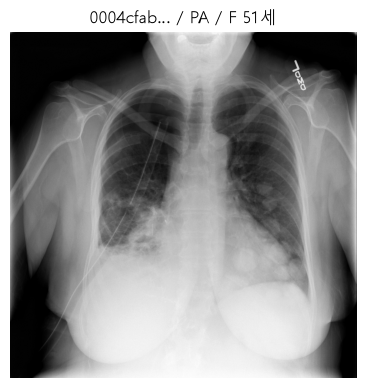


(전체 메타데이터를 보려면 다음 줄의 #을 지우고 실행)


In [3]:
f0 = sorted(IMG_DIR.glob("*.dcm"))[0]
ds = pydicom.dcmread(f0)

print("=== 메타데이터 (일부) ===")
for tag in ["PatientID", "PatientSex", "PatientAge", "ViewPosition", "Modality", "BodyPartExamined",
            "Rows", "Columns", "PixelSpacing", "BitsStored", "PhotometricInterpretation"]:
    print(f"  {tag:<26}: {getattr(ds, tag, '(없음)')}")

img = ds.pixel_array
print(f"\n=== 픽셀 ===\n  shape {img.shape}, dtype {img.dtype}, 값 범위 {img.min()} ~ {img.max()}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(img, cmap="gray"); ax.set_title(f"{f0.stem[:8]}… / {ds.ViewPosition} / {ds.PatientSex} {ds.PatientAge}세"); ax.axis("off")
plt.show()
print("\n(전체 메타데이터를 보려면 다음 줄의 #을 지우고 실행)")
# print(ds)

**DICOM 읽는 법 정리**
- `pydicom.dcmread(경로)` → 파일 열기, `ds.태그이름` → 메타데이터, `ds.pixel_array` → numpy 이미지
- **PhotometricInterpretation**: `MONOCHROME2` = 숫자가 클수록 밝음(일반적), `MONOCHROME1` = 반대(뒤집어서 봐야 함). 병원 데이터에선 섞여 있어서 꼭 확인해야 해요
- 이 데이터는 이미 8비트(0~255)로 저장돼 있어서 쉬운 편이에요. **CT는 보통 12~16비트**(HU 값)라 *윈도잉*(보고 싶은 밝기 범위만 잘라 보기)이 필요해요 → 프로젝트 4에서 다뤄요

## 3. 라벨 EDA: 폐렴 비율, 박스 개수·위치·크기

> 🎯 **왜 하나요?** 검출 모델을 설계하려면 *"박스가 몇 개, 얼마나 크게, 어디에"* 나오는지 알아야 해요.  
> 그리고 이 데이터에는 **3가지 상세 클래스**가 있어요. 특히 **"Not Normal, 폐렴은 아님"**은 정상과 다르게 생겨서 모델이 폐렴으로 헷갈리기 쉬운 *어려운 음성(hard negative)*이에요.

In [ ]:
lab = pd.read_csv(LABELS_CSV)
cls = pd.read_csv(CLASS_CSV).drop_duplicates("patientId")
print("라벨 파일 (한 줄 = 박스 하나, 폐렴 없으면 박스 칸이 비어 있음):")
# 해당 박스의 x, y 좌표를 출력함 
display(lab.head())

pat = lab.groupby("patientId").agg(Target=("Target", "max"), n_boxes=("x", "count")).reset_index().merge(cls, on="patientId")
print(f"\n환자(=사진) 수: {len(pat):,} / 박스 수: {lab['x'].notna().sum():,}")
# 환자 26684명의 사진 중에서 빨간 네모의 수가 9555개 (22.5%)
# 다만 폐렴 사진에만 있으므로 폐렴 사진인 6012장 중에 네모 박스가 9555개 있는것
print(f"폐렴(Target=1) 비율: {pat['Target'].mean():.1%}\n")
print("상세 클래스 분포:")
# Target == 1: 폐렴의심 (박스있음) | Target == 0: Normal(정상), No Lung Opacity / Not Normal (폐렴 음영은 없으나 다른 이상이 있음)

display(pd.crosstab(pat["class"], pat["Target"], margins=True, margins_name="합계"))
print("폐렴 사진 1장당 박스 개수:")
print(pat.loc[pat["Target"] == 1, "n_boxes"].value_counts().sort_index().to_string())

라벨 파일 (한 줄 = 박스 하나, 폐렴 없으면 박스 칸이 비어 있음):


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1



환자(=사진) 수: 26,684 / 박스 수: 9,555
폐렴(Target=1) 비율: 22.5%

상세 클래스 분포:


Target,0,1,합계
class,,,
Lung Opacity,0,6012,6012
No Lung Opacity / Not Normal,11821,0,11821
Normal,8851,0,8851
합계,20672,6012,26684


폐렴 사진 1장당 박스 개수:
n_boxes
1    2614
2    3266
3     119
4      13


### 📝 메모: 박스 위치·크기
- **위치**: 박스 중심이 두 덩어리 (가로 ~300, ~700 / 세로 ~450~650) = 양쪽 폐의 중간~아래쪽
  - 가운데(심장·척추 자리)와 폐 바깥엔 거의 없음 → 해부학적으로 위치가 정해져 있음
  - 좌우 대칭 → 좌우 반전 증강 OK
- **크기**: 가로·세로 양의 상관. 대부분 **세로로 길쭉한 직사각형** (가로 ~100~400, 세로 ~100~900) — 폐 모양을 따라 그려짐
- **면적**: 이미지의 2~10%가 대부분 (최빈 3~5%), 큰 것은 30% 이상 → 640×640에서도 충분히 큼 (작은 물체 검출 문제 아님)

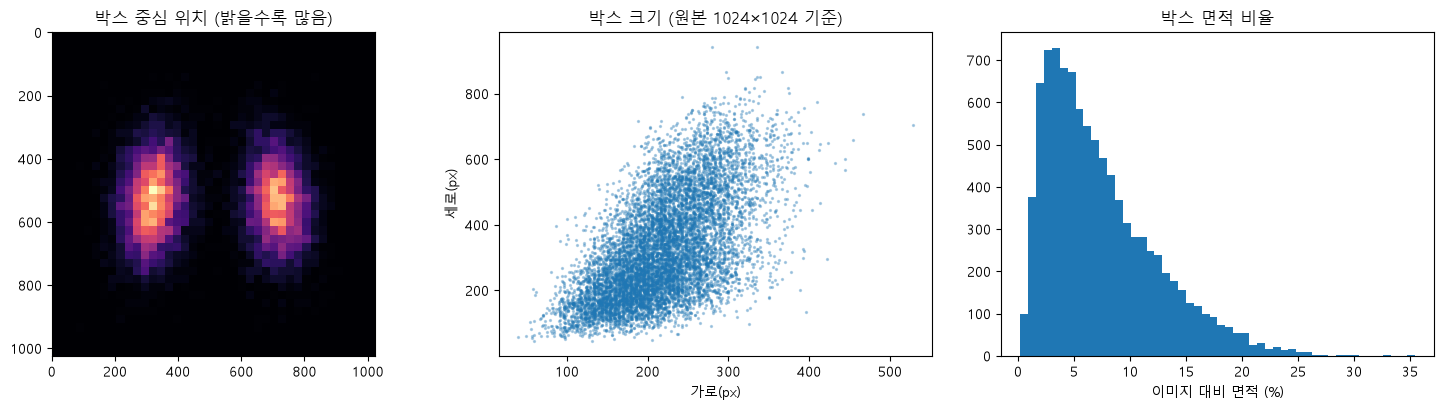

         count   mean    std   min    25%    50%    75%    max
width   9555.0  218.0   59.0  40.0  177.0  217.0  259.0  528.0
height  9555.0  329.0  158.0  45.0  203.0  298.0  438.0  942.0

박스 면적: 이미지의 중앙값 6.2% (작은 결절 검출과 달리 꽤 큰 편)


In [ ]:
b = lab.dropna(subset=["x"]).copy()
b["cx"], b["cy"] = b["x"] + b["width"] / 2, b["y"] + b["height"] / 2
b["area_ratio"] = b["width"] * b["height"] / (1024 * 1024)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].hist2d(b["cx"], b["cy"], bins=40, range=[[0, 1024], [0, 1024]], cmap="magma")
axes[0].invert_yaxis(); axes[0].set_aspect("equal"); axes[0].set_title("박스 중심 위치 (밝을수록 많음)")
axes[1].scatter(b["width"], b["height"], s=2, alpha=.3); axes[1].set_xlabel("가로(px)"); axes[1].set_ylabel("세로(px)")
axes[1].set_title("박스 크기 (원본 1024×1024 기준)")
axes[2].hist(b["area_ratio"] * 100, bins=50); axes[2].set_xlabel("이미지 대비 면적 (%)"); axes[2].set_title("박스 면적 비율")
plt.tight_layout(); plt.show()
print(b[["width", "height"]].describe().round(0).T)
print(f"\n박스 면적: 이미지의 중앙값 {b['area_ratio'].median():.1%} (작은 결절 검출과 달리 꽤 큰 편)")

### 📝 메모: AP vs PA
- PA (뒤→앞): 서서 촬영, 외래·검진의 표준. 심장 크기 정확, 어깨뼈가 폐 밖, 폐가 잘 펴짐
- AP (앞→뒤): 누워서/앉아서, 이동식 장비(portable)로 병실·중환자실에서. 심장이 커 보이고 폐가 뿌옇게 보임
- **AP = 거동이 어려운(더 아픈) 환자가 많음** → 폐렴 비율이 높을 것으로 예상
- 예시 그림에서도 확인: 폐렴 사진에 "AP PORTABLE" 글자, 심전도 전극·튜브가 많고 / 정상 사진은 PA 특징(선 없음, 폐가 검고 크게 펴짐, 위 공기방울)
- → 글자·의료기구·자세 차이가 **폐렴의 지름길**이 될 수 있음 (프로젝트 1의 notumor-T2와 같은 종류)

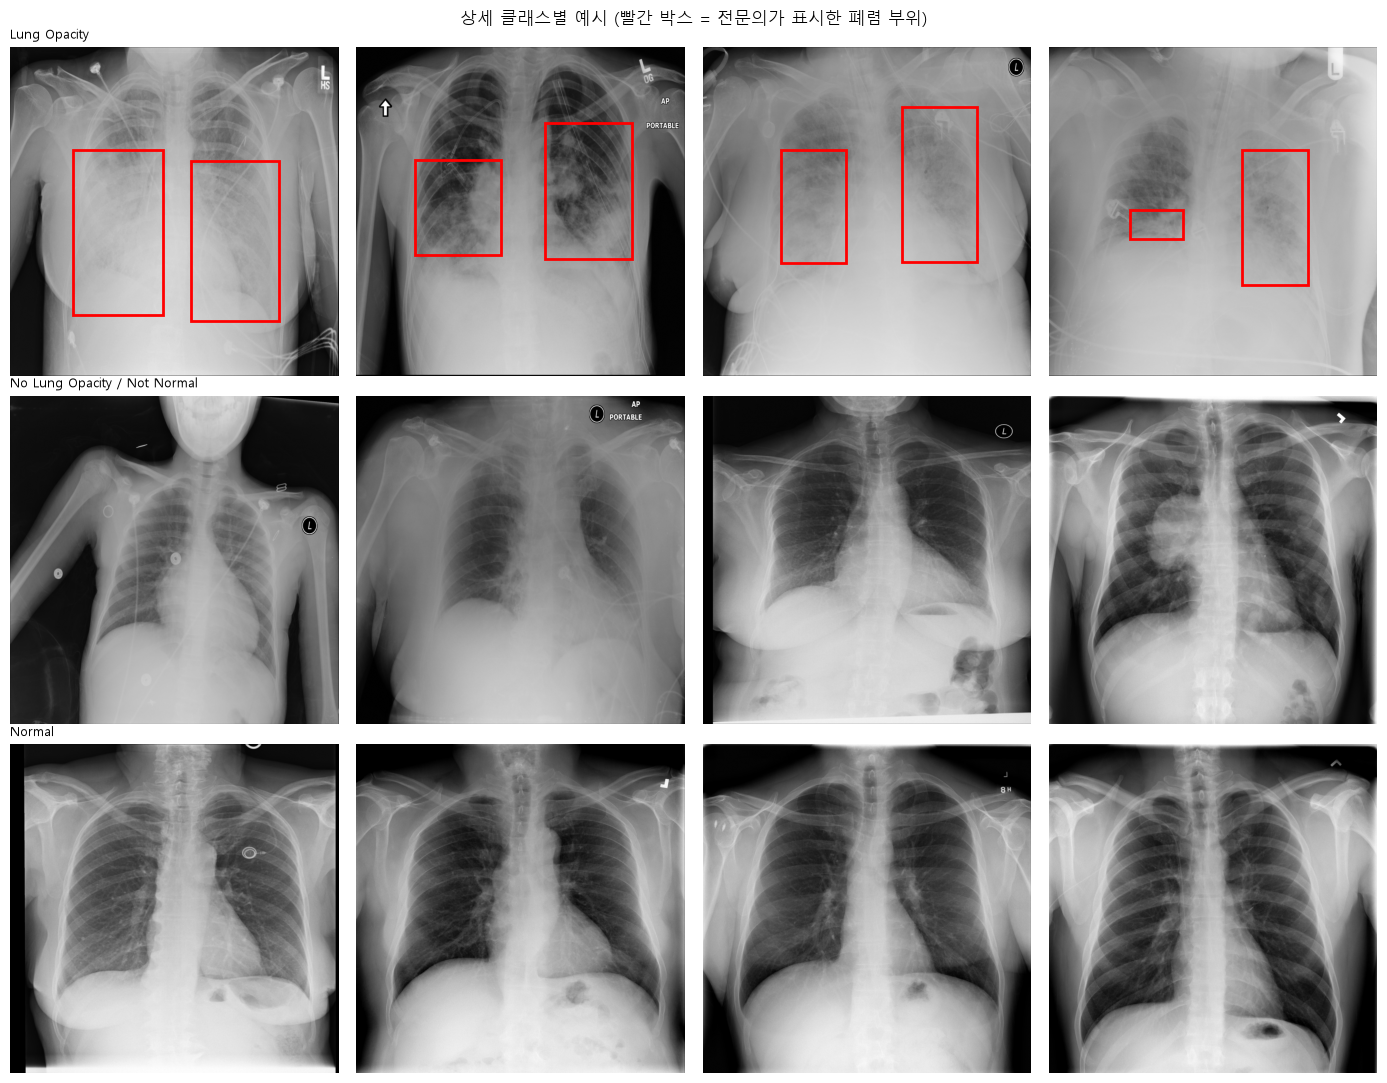

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for r, c in enumerate(["Lung Opacity", "No Lung Opacity / Not Normal", "Normal"]):
    ids = pat.loc[pat["class"] == c, "patientId"].sample(4, random_state=SEED)
    for k, pid in enumerate(ids):
        ax = axes[r, k]; ax.imshow(pydicom.dcmread(IMG_DIR / f"{pid}.dcm").pixel_array, cmap="gray"); ax.axis("off")
        for _, bb in lab[(lab["patientId"] == pid) & lab["x"].notna()].iterrows():
            ax.add_patch(patches.Rectangle((bb.x, bb.y), bb.width, bb.height, fill=False, ec="red", lw=2))
        ax.set_title(c if k == 0 else "", fontsize=9, loc="left")
plt.suptitle("상세 클래스별 예시 (빨간 박스 = 전문의가 표시한 폐렴 부위)"); plt.tight_layout(); plt.show()

## 4. 메타데이터 EDA: 촬영 자세(AP/PA)와 폐렴 ⭐

> 🎯 **왜 하나요?** 프로젝트 1에서 배운 **지름길** 확인이에요.  
> 흉부 X-ray는 촬영 자세가 두 가지예요.
> - **PA** (Posterior→Anterior): 환자가 **서서** 등 쪽에서 찍음. 외래·건강한 환자에게 표준
> - **AP** (Anterior→Posterior): **누워서/앉아서** 앞에서 찍음. 거동이 어려운 **입원·중환자**에게 주로 사용 → 심장이 크게 보이는 등 생김새가 다름
>
> 만약 AP 사진에 폐렴이 훨씬 많다면, 모델은 폐가 아니라 **"AP 사진처럼 생겼다"**로 폐렴을 맞힐 수 있어요.  
> 전체 DICOM의 **헤더만** 읽어요 (`stop_before_pixels=True` → 픽셀은 안 읽어서 빠름).

DICOM 헤더 읽기: 100%|██████████| 26684/26684 [00:41<00:00, 643.73it/s]


촬영 자세별 폐렴 비율:


,사진수,폐렴비율
view,,
AP,12173,38.3%
PA,14511,9.3%


촬영 자세 × 상세 클래스 (행 기준 비율):


class,Lung Opacity,No Lung Opacity / Not Normal,Normal
view,,,
AP,38.3,48.2,13.4
PA,9.3,41.0,49.7


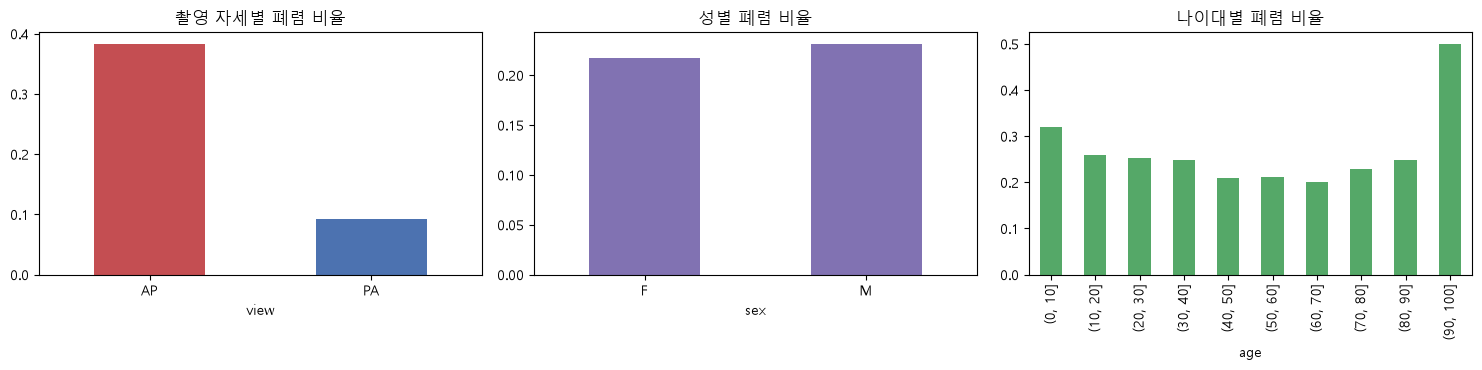

나이 이상치 (100세 초과): [148, 151, 153, 150, 155] ← DICOM 메타데이터에도 입력 오류가 있어요


In [7]:
def read_meta(pid):
    d = pydicom.dcmread(IMG_DIR / f"{pid}.dcm", stop_before_pixels=True)
    return {"patientId": pid, "view": d.ViewPosition, "sex": d.PatientSex, "age": int(d.PatientAge),
            "H": int(d.Rows), "W": int(d.Columns)}

with ThreadPoolExecutor(8) as ex:
    meta = pd.DataFrame(list(tqdm(ex.map(read_meta, pat["patientId"]), total=len(pat), desc="DICOM 헤더 읽기")))
pat = pat.merge(meta, on="patientId")

print("촬영 자세별 폐렴 비율:")
v = pat.groupby("view").agg(사진수=("Target", "size"), 폐렴비율=("Target", "mean"))
display(v.style.format({"폐렴비율": "{:.1%}"}))
print("촬영 자세 × 상세 클래스 (행 기준 비율):")
display((pd.crosstab(pat["view"], pat["class"], normalize="index") * 100).round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
pat.groupby("view")["Target"].mean().plot.bar(ax=axes[0], color=["#C44E52", "#4C72B0"], rot=0); axes[0].set_title("촬영 자세별 폐렴 비율")
pat.groupby("sex")["Target"].mean().plot.bar(ax=axes[1], rot=0, color="#8172B2"); axes[1].set_title("성별 폐렴 비율")
pat[pat["age"] <= 100].groupby(pd.cut(pat["age"], range(0, 101, 10)), observed=True)["Target"].mean().plot.bar(ax=axes[2], color="#55A868")
axes[2].set_title("나이대별 폐렴 비율"); plt.tight_layout(); plt.show()
print("나이 이상치 (100세 초과):", pat.loc[pat["age"] > 100, "age"].tolist(), "← DICOM 메타데이터에도 입력 오류가 있어요")

### 📝 메모: 메타데이터 EDA (전체 26,684명)
- **촬영 자세**: AP 12,173장 폐렴 **38.3%** vs PA 14,511장 **9.3%** → 약 4배
  - "AP면 폐렴" 규칙만으로 민감도 ~78%, 특이도 ~64% (AUROC ~0.71) → **폐를 안 보고도 상당히 맞힘 = 강한 지름길 후보**
- **자세 × 상세 클래스**: AP는 Normal이 13.4%뿐 (PA는 49.7%), AP 음성 대부분이 Not Normal(48.2%)
  - → AP 오탐이 많아도 "폐의 다른 이상" 때문일 수 있음 → **Normal 음성끼리 AP vs PA를 비교**해야 지름길 판단 가능 (노트북 2의 5번)
- **성별**: F ~22%, M ~23% → 차이 거의 없음
- **나이**: 0~10세 32%, 90~100세 50%, 40~70세 ~20% (U자). 단 90~100세는 표본이 적어 불안정
- **나이 이상치**: 148, 150, 151, 153, 155세 → 메타데이터 입력 오류, 분석 시 결측 처리 필요

## 5. 환자 단위 train / val / test 분할

> 🎯 **왜 하나요?** 프로젝트 1의 가장 큰 한계가 *"환자 ID가 없어 같은 환자가 train·test에 섞였을 수 있다"*였어요.  
> 이 데이터는 **환자 1명 = 사진 1장**이고 `patientId`가 있어서, **환자 기준으로 나누면 누수가 원천적으로 없어요.**  
> (실제 병원 데이터는 환자 1명이 사진 여러 장이라, 반드시 `patientId`로 묶어서 나눠야 해요 → `GroupShuffleSplit` 등)
>
> 비율은 80 : 10 : 10, **상세 클래스 3종의 비율을 유지**(stratify)해요.

In [8]:
tr, tmp = train_test_split(pat, test_size=0.2, stratify=pat["class"], random_state=SEED)
va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["class"], random_state=SEED)
pat["split"] = "train"; pat.loc[va.index, "split"] = "val"; pat.loc[te.index, "split"] = "test"

assert pat.groupby("patientId")["split"].nunique().max() == 1    # 같은 환자가 두 split에 있으면 에러
print("✅ 환자가 두 split에 겹치지 않음 확인\n")
display(pd.crosstab(pat["class"], pat["split"], margins=True, margins_name="합계")[["train", "val", "test", "합계"]])

✅ 환자가 두 split에 겹치지 않음 확인



split,train,val,test,합계
class,,,,
Lung Opacity,4809,601,602,6012
No Lung Opacity / Not Normal,9457,1182,1182,11821
Normal,7081,885,885,8851
합계,21347,2668,2669,26684


## 6. YOLO 형식으로 변환 (DICOM → PNG + 라벨 txt)

> 🎯 **YOLO가 원하는 형식**
> ```
> yolo_data/
> ├── images/train/환자ID.png      ← 이미지
> ├── labels/train/환자ID.txt      ← 박스 정보 (폐렴 없으면 빈 파일)
> └── data.yaml                    ← "이미지는 어디, 클래스 이름은 뭐" 설정 파일
> ```
> 라벨 txt는 박스 하나당 한 줄: **`클래스번호 중심x 중심y 가로 세로`** — 전부 **0~1로 정규화**(이미지 크기로 나눔)  
> 원본 CSV는 `x, y`가 **왼쪽 위 꼭짓점**이고 픽셀 단위라, **중심점으로 바꾸고 1024로 나눠야** 해요. 여기서 실수가 가장 많이 나요 → 7번에서 꼭 확인
>
> 🎯 **train은 일부만 써요 (`NEG_RATIO`)**  
> 폐렴 없는 사진이 약 78%라 다 쓰면 학습이 오래 걸리고 대부분 "박스 없음"만 배워요.  
> train은 **폐렴 사진 전부 + 같은 수의 음성 사진**만 써요. 단 **val·test는 전부(실제 비율 그대로)** 써요 → *평가는 현실과 같은 조건에서* 해야 하니까요.  
> 음성 중 **"Not Normal"(어려운 음성)이 그대로 포함**되게 무작위로 뽑아요.
> YOLO는 모델이 무거워서 학습이 이전보다 2배 이상 걸릴 수 있고, 음성사진에서 얻는 정보가 적음. 
> YOLO가 얻는 건 박스를 어디에 어떻게 그릴지 (양성에서 학습), 여기에는 박스 그리지마 (음성에서 학습, 양성에서도 가능) --> 양성이 가성비가 좋음
> 예상되는 문제점: 음성을 덜 봐서 오탐이 늘 수 있음 (FP), 점수가 부풀려짐 (학습때의 비율은 5:5인데 실제는 8:2정도라서 점수가 전반적으로 높게나옴)
> 그래서 threshold는 val set에서 정하고 평가도 실제 비율의 test set에서 진행함 

> 🎯 **640×640으로 줄여 저장**: YOLO 학습 크기에 맞춰서 디스크·시간 절약 (좌표는 0~1 정규화라 크기를 바꿔도 그대로 유효)

In [9]:
NEG_RATIO = 1.0      # train 음성 사진 수 = 양성 수 × NEG_RATIO  (전부 쓰려면 None)
SAVE_SIZE = 640
CLASS_NAMES = ["pneumonia"]

train_pos = pat[(pat["split"] == "train") & (pat["Target"] == 1)]
train_neg = pat[(pat["split"] == "train") & (pat["Target"] == 0)]
if NEG_RATIO is not None:
    train_neg = train_neg.sample(min(len(train_neg), int(len(train_pos) * NEG_RATIO)), random_state=SEED)
use = pd.concat([train_pos, train_neg, pat[pat["split"] != "train"]])
print(f"변환할 사진: {len(use):,}장  (train {len(train_pos) + len(train_neg):,} = 양성 {len(train_pos):,} + 음성 {len(train_neg):,} / "
      f"val {(use['split'] == 'val').sum():,} / test {(use['split'] == 'test').sum():,})")

boxes_by_pid = {pid: g[["x", "y", "width", "height"]].values for pid, g in lab.dropna(subset=["x"]).groupby("patientId")}

def convert(row):
    pid, split = row["patientId"], row["split"]
    img_p = YOLO_DIR / "images" / split / f"{pid}.png"
    lbl_p = YOLO_DIR / "labels" / split / f"{pid}.txt"
    H, W = row["H"], row["W"]                       # 원본 크기 (DICOM 헤더에서 읽어둔 값)
    if not img_p.exists():                         # 이미 변환된 건 건너뜀 → 중간에 끊겨도 이어서 가능
        a = pydicom.dcmread(IMG_DIR / f"{pid}.dcm").pixel_array
        Image.fromarray(a).resize((SAVE_SIZE, SAVE_SIZE), Image.BILINEAR).save(img_p)
    lines = []
    for x, y, w, h in boxes_by_pid.get(pid, []):
        lines.append(f"0 {(x + w / 2) / W:.6f} {(y + h / 2) / H:.6f} {w / W:.6f} {h / H:.6f}")   # 왼쪽위 → 중심, 픽셀 → 0~1
    lbl_p.write_text("\n".join(lines))

for s in ["train", "val", "test"]:
    (YOLO_DIR / "images" / s).mkdir(parents=True, exist_ok=True); (YOLO_DIR / "labels" / s).mkdir(parents=True, exist_ok=True)
with ThreadPoolExecutor(8) as ex:
    list(tqdm(ex.map(convert, [r for _, r in use.iterrows()]), total=len(use), desc="DICOM → PNG + txt"))

(YOLO_DIR / "data.yaml").write_text(
    f"path: {YOLO_DIR.as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\n"
    f"names:\n  0: pneumonia\n", encoding="utf-8")
use.to_csv(OUT / "p2_split_meta.csv", index=False, encoding="utf-8-sig")
print("\n✅ 완료:", YOLO_DIR / "data.yaml")
print((YOLO_DIR / "data.yaml").read_text())

변환할 사진: 14,955장  (train 9,618 = 양성 4,809 + 음성 4,809 / val 2,668 / test 2,669)


DICOM → PNG + txt: 100%|██████████| 14955/14955 [01:36<00:00, 155.37it/s]


✅ 완료: D:\yerimlee\medimg-study\outputs\p2\yolo_data\data.yaml
path: D:/yerimlee/medimg-study/outputs/p2/yolo_data
train: images/train
val: images/val
test: images/test
names:
  0: pneumonia



## 7. 변환 검증: 라벨 txt를 다시 그려보기 ⭐

> 🎯 **왜 하나요?** 좌표 변환이 틀려도 **에러는 안 나요.** 모델은 엉뚱한 위치를 열심히 학습하고 성능만 이상하게 낮게 나와요.  
> 그래서 **변환된 PNG + txt를 다시 읽어서 박스를 그리고**, 3번에서 원본 DICOM에 그린 박스와 같은 위치인지 눈으로 확인해요.  
> 왼쪽(원본 DICOM + CSV 좌표)과 오른쪽(변환된 PNG + YOLO txt)의 빨간 박스 위치가 같아야 해요.

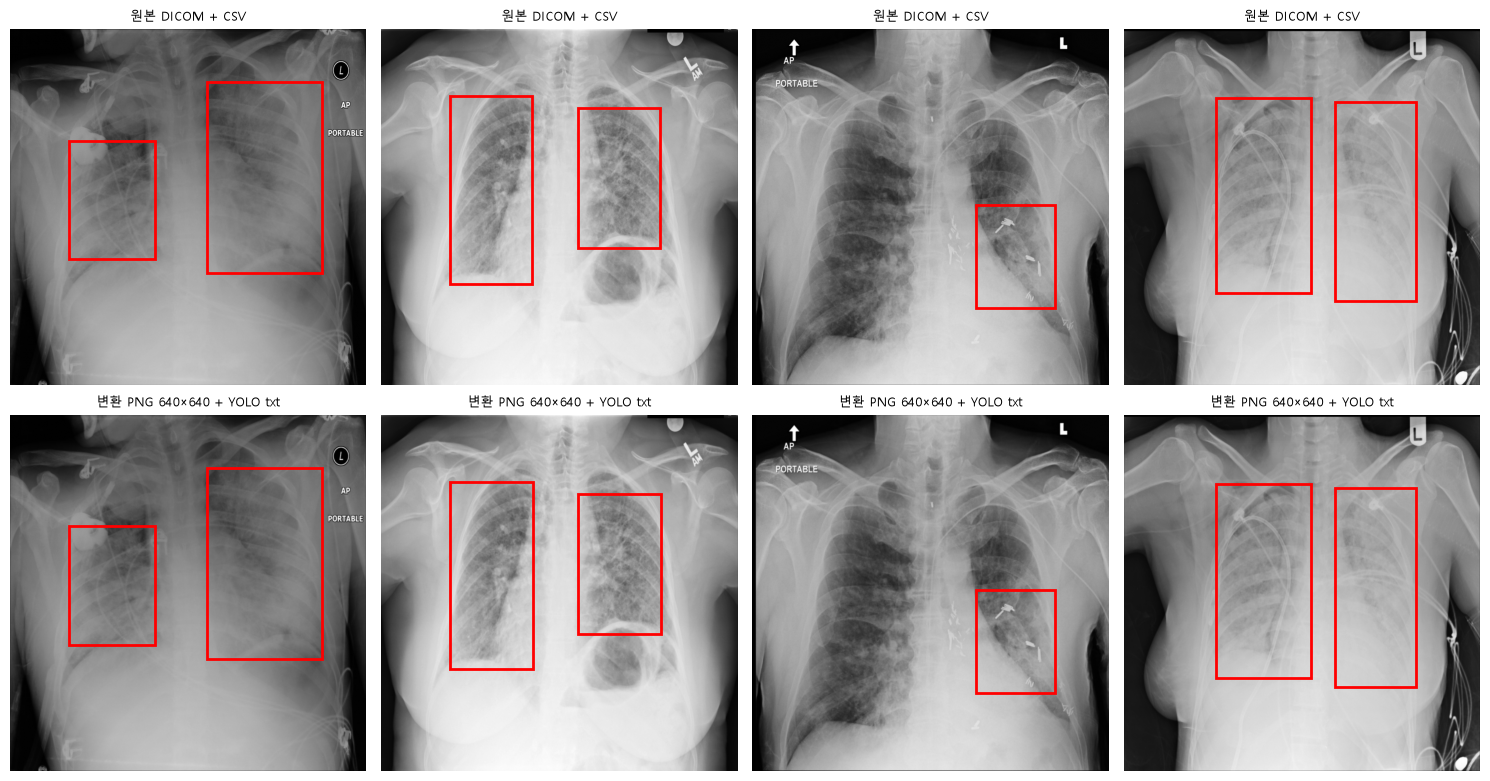

train: 이미지 9,618 / 박스 있는 사진 4,809 (50.0%)
val  : 이미지 2,668 / 박스 있는 사진 601 (22.5%)
test : 이미지 2,669 / 박스 있는 사진 602 (22.6%)


In [10]:
sample = use[(use["split"] == "train") & (use["Target"] == 1)].sample(4, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for k, (_, r) in enumerate(sample.iterrows()):
    pid = r["patientId"]
    a = pydicom.dcmread(IMG_DIR / f"{pid}.dcm").pixel_array
    axes[0, k].imshow(a, cmap="gray"); axes[0, k].set_title("원본 DICOM + CSV", fontsize=9)
    for x, y, w, h in boxes_by_pid[pid]:
        axes[0, k].add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="red", lw=2))
    im = np.asarray(Image.open(YOLO_DIR / "images" / "train" / f"{pid}.png")); S = im.shape[0]
    axes[1, k].imshow(im, cmap="gray"); axes[1, k].set_title(f"변환 PNG {S}×{S} + YOLO txt", fontsize=9)
    for line in (YOLO_DIR / "labels" / "train" / f"{pid}.txt").read_text().splitlines():
        _, cx, cy, w, h = map(float, line.split())
        axes[1, k].add_patch(patches.Rectangle(((cx - w / 2) * S, (cy - h / 2) * S), w * S, h * S, fill=False, ec="red", lw=2))
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

for s in ["train", "val", "test"]:
    n_img = len(list((YOLO_DIR / "images" / s).glob("*.png")))
    n_pos = sum(1 for p in (YOLO_DIR / "labels" / s).glob("*.txt") if p.read_text().strip())
    print(f"{s:<5}: 이미지 {n_img:,} / 박스 있는 사진 {n_pos:,} ({n_pos / n_img:.1%})")

## ✍️ 정리 & 생각해볼 질문

1. DICOM 메타데이터 중 **연구에 쓸 수 있는 정보**는 뭐가 있었나? 반대로 **조심해야 할 정보**는? (나이 이상치 등)
2. 폐렴 비율은? 폐렴 사진 1장당 박스는 보통 몇 개? 박스 위치는 어디에 몰려 있었나 (왜 그럴까)?
3. **AP와 PA의 폐렴 비율 차이**는? 이게 모델에 어떤 지름길이 될 수 있을까? 프로젝트 1의 notumor(T2 영상)와 비교하면?
4. "No Lung Opacity / Not Normal"은 몇 %? 이 사진들에서 모델이 오탐(박스를 잘못 그림)을 많이 낼까?
5. train만 음성을 줄인 이유는? val·test까지 줄이면 무슨 문제가 생길까?
6. 7번 검증에서 박스 위치가 일치했나?

**메모:**
- 
